In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

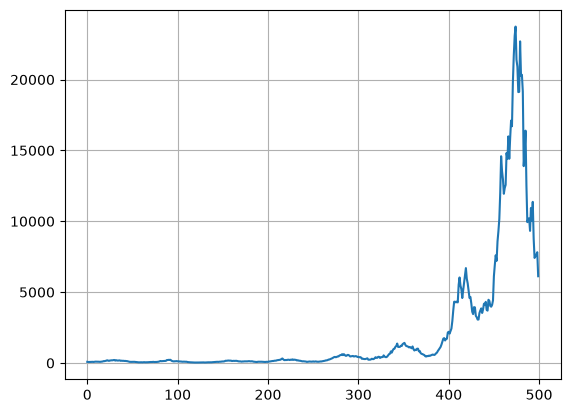

In [4]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [5]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

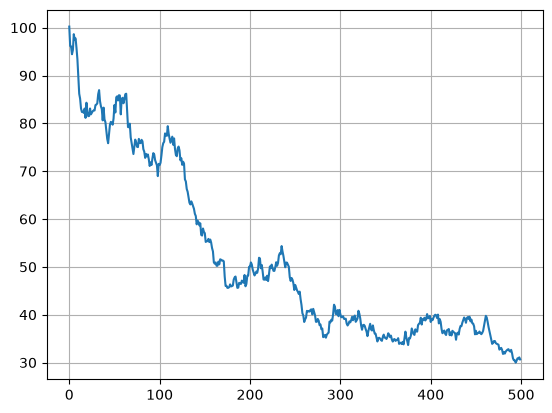

In [6]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [7]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

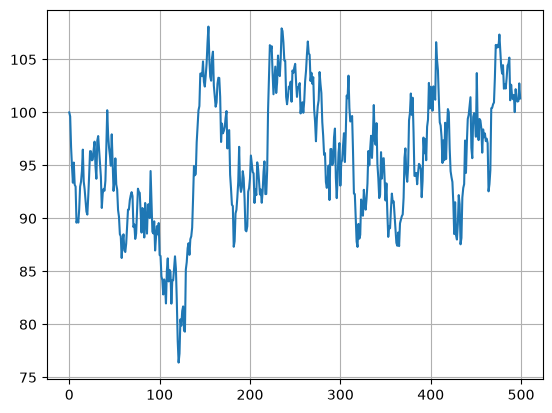

In [8]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [9]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

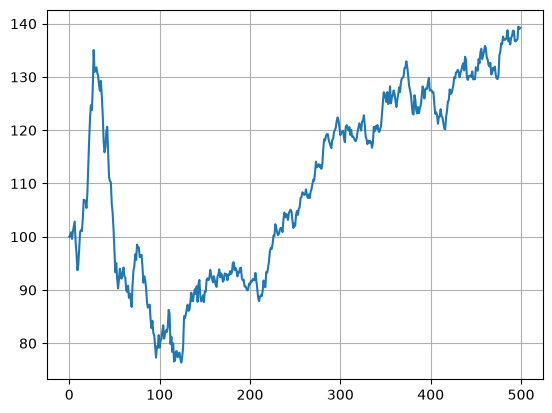

In [10]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [11]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [12]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

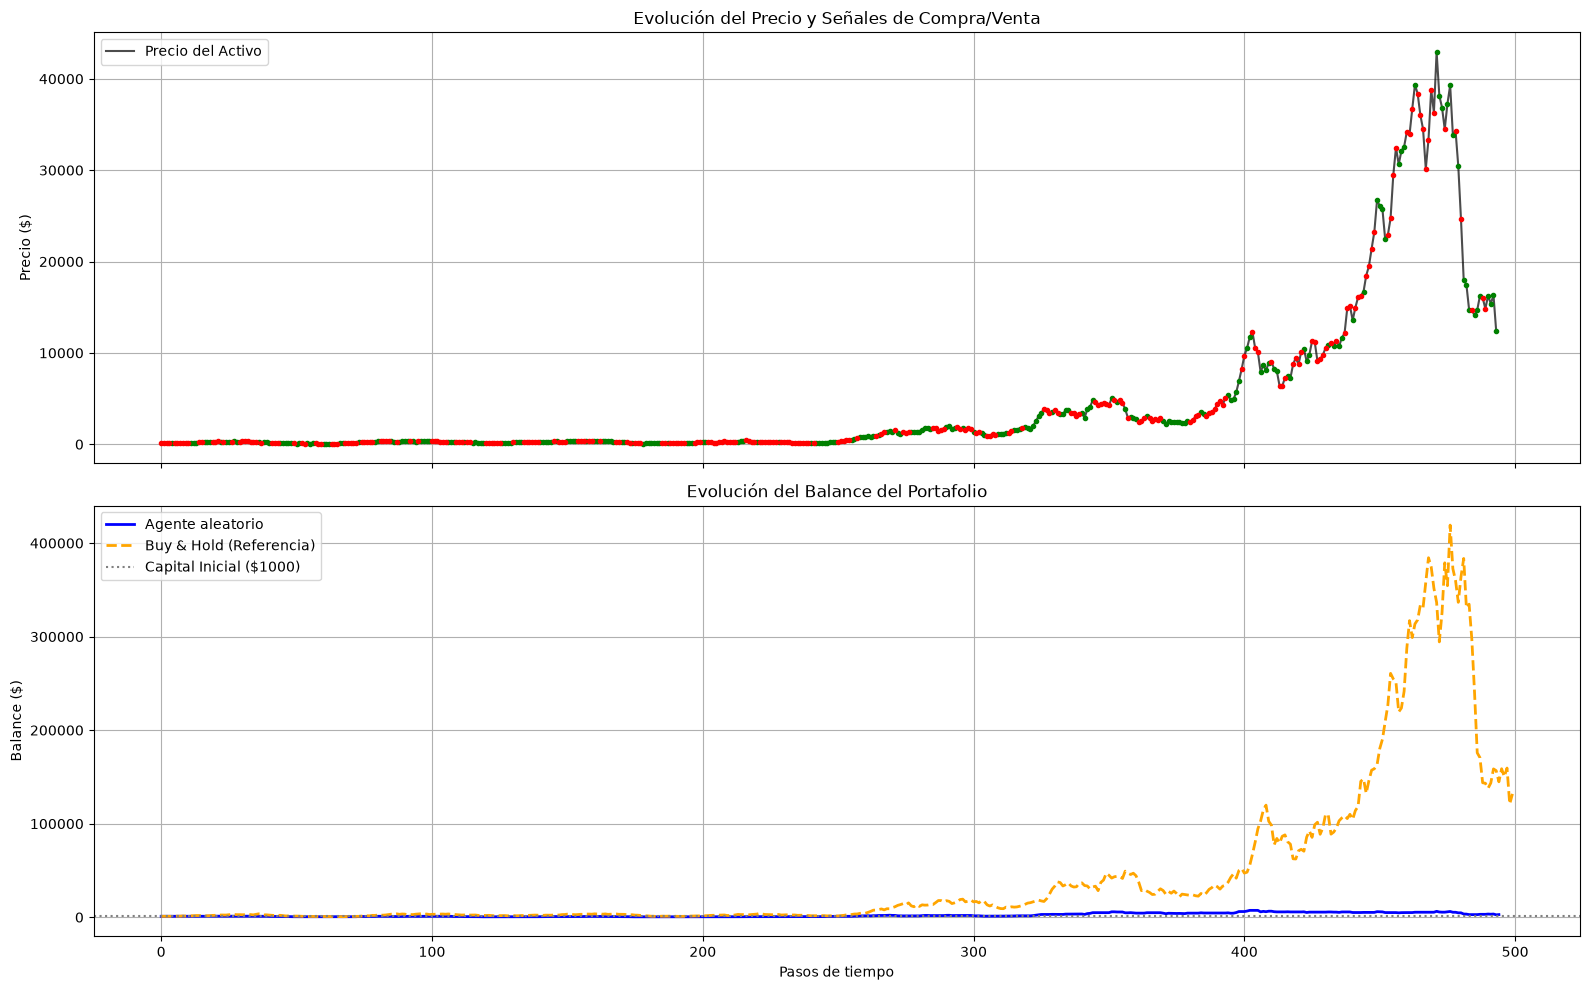

In [13]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *Q-Learning* y *Sarsa*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **29/10/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a luis.lago@uam.es antes de la clase del jueves 29 de octubre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 27 de octubre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

---
# Solución: agente **Sarsa**

A partir de aquí se implementa el algoritmo **Sarsa** (control TD *on-policy*). La solución se divide en dos bloques:

- **Infraestructura común** (secciones 1 y 2): generación de series de *train / validación / test*, funciones de evaluación, *baselines* (agente aleatorio y *buy & hold*) y discretización del estado. Es independiente del algoritmo, de modo que se puede reutilizar tal cual para *Q-Learning*.
- **Sarsa** (secciones 3 en adelante): agente, entrenamiento, ajuste de hiperparámetros, resultados y análisis.

## 1. Infraestructura común

In [14]:
import os
import time
import bisect
import random

import pandas as pd

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:          # sin joblib todo funciona igual, pero los experimentos se ejecutan en serie
    HAY_JOBLIB = False

N_STEPS = 500                # longitud de cada serie de precios
CAPITAL_INICIAL = 1000.0
N_JOBS = max(1, (os.cpu_count() or 2) - 1)

# Semillas distintas para que las series de ajuste, validación y test no se solapen nunca
SEED_AJUSTE = 30_000         # series para fijar los intervalos de discretización
SEED_VAL = 20_000            # validación: selección de hiperparámetros
SEED_TEST = 10_000           # test: solo para la evaluación final
N_VAL = 100
N_TEST = 200

GENERADORES = {
    "Tendencia + ciclo": generar_precios,
    "Browniano": generar_precios_browniano,
    "Reversión a la media": generar_precios_reversion_media,
    "Regímenes": generar_precios_regimenes,
}


def crear_series(generador, n_series, n_steps=N_STEPS, seed=0):
    """Conjunto fijo y reproducible de series (no altera el generador aleatorio global)."""
    estado = np.random.get_state()
    np.random.seed(seed)
    series = [generador(n_steps) for _ in range(n_series)]
    np.random.set_state(estado)
    return series

### Evaluación de políticas y *baselines*

`rollout` ejecuta una política (cualquier función `observación -> acción`) sobre una serie de precios con el entorno original. `evaluar` lo repite sobre un conjunto de series y devuelve el balance final y el número de operaciones de cada una. Como los *baselines* y los agentes se evalúan **sobre las mismas series**, las comparaciones son pareadas.

In [15]:
def rollout(precios, politica, env_cls=SimpleTradingEnv):
    env = env_cls(precios)
    obs, _ = env.reset()
    terminated = truncated = False
    n_operaciones = 0
    balances, posiciones = [env.balance], []

    while not (terminated or truncated):
        pos_antes = env.position
        posiciones.append(pos_antes)
        obs, _, terminated, truncated, _ = env.step(politica(obs))
        n_operaciones += int(env.position != pos_antes)
        balances.append(env.balance)

    return {"final": env.balance, "operaciones": n_operaciones,
            "balances": np.array(balances), "posiciones": np.array(posiciones)}


def evaluar(politica, series, env_cls=SimpleTradingEnv):
    res = [rollout(p, politica, env_cls) for p in series]
    return {"final": np.array([r["final"] for r in res]),
            "operaciones": np.array([r["operaciones"] for r in res])}


class PoliticaAleatoria:
    """Agente aleatorio: acción uniforme entre las 3 posibles (equivale a env.action_space.sample())."""
    def __init__(self, seed=0):
        self.rng = random.Random(seed)

    def __call__(self, obs):
        return self.rng.randrange(3)


def comprar_y_mantener(obs):
    """Buy & hold: compra en el primer paso (posición = 0) y no vuelve a operar."""
    return 2 if obs[1] == 0 else 1


def resumen(res, res_bh):
    """Métricas de un conjunto de episodios; `res_bh` son los resultados de buy & hold en las mismas series."""
    final, n = res["final"], len(res["final"])
    dif = final - res_bh["final"]
    return {
        "Balance medio ($)": final.mean(),
        "Mediana ($)": np.median(final),
        "Retorno log medio": np.log(final / CAPITAL_INICIAL).mean(),
        "Δ vs B&H ($)": dif.mean(),
        "EE Δ vs B&H": dif.std(ddof=1) / np.sqrt(n),
        "% series > B&H": 100 * (dif > 0).mean(),
        "Operaciones": res["operaciones"].mean(),
    }


def ejecutar(funcion, tareas):
    """Ejecuta `funcion(**tarea)` para cada tarea, en paralelo si hay joblib."""
    if HAY_JOBLIB and N_JOBS > 1 and len(tareas) > 1:
        return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(funcion)(**t) for t in tareas)
    return [funcion(**t) for t in tareas]

## 2. Discretización del estado

El entorno devuelve `(tendencia, posición)` con la tendencia **continua**, pero Sarsa tabular necesita un número finito de estados. Discretizamos la tendencia en `n_bins` intervalos y mantenemos la posición (0/1), de modo que hay `2 · n_bins` estados.

**Decisión de diseño:** los límites de los intervalos son *cuantiles* de la distribución de la tendencia (y no una rejilla uniforme). Las tendencias son muy pequeñas (del orden de 1e-2) y están muy concentradas alrededor de 0, así que una rejilla uniforme dejaría casi todos los estados sin visitar; con cuantiles cada intervalo recibe aproximadamente la misma cantidad de datos. Como la tendencia depende solo de los precios (no de las acciones del agente), los cuantiles se pueden estimar sin ningún agente, con series generadas por el propio generador de precios.

In [16]:
class TrendDiscretizer:
    """Codifica la observación (tendencia, posición) como un entero: estado = 2 * intervalo + posición."""

    def __init__(self, limites, centros=None):
        self.limites = [float(x) for x in limites]
        self.n_bins = len(self.limites) + 1
        self.n_estados = 2 * self.n_bins
        self.centros = centros      # tendencia mediana de cada intervalo (solo para representar)

    @classmethod
    def ajustar(cls, generador, n_bins, n_series=40, n_steps=N_STEPS, seed=SEED_AJUSTE):
        tendencias = []
        for precios in crear_series(generador, n_series, n_steps, seed):
            env = SimpleTradingEnv(precios)
            obs, _ = env.reset()
            terminated = False
            tendencias.append(obs[0])
            while not terminated:
                obs, _, terminated, _, _ = env.step(1)
                tendencias.append(obs[0])
        tendencias = np.array(tendencias, dtype=float)

        limites = np.unique(np.quantile(tendencias, np.linspace(0, 1, n_bins + 1)[1:-1]))
        intervalo = np.searchsorted(limites, tendencias, side="right")
        centros = [np.median(tendencias[intervalo == i]) if np.any(intervalo == i) else np.nan
                   for i in range(len(limites) + 1)]
        return cls(limites, centros)

    def __call__(self, obs):
        return 2 * bisect.bisect_right(self.limites, float(obs[0])) + int(obs[1])

### ¿Qué información contiene la tendencia?

**Arriba:** distribución de la tendencia en cada generador con los límites de 10 intervalos por cuantiles; la forma y la escala cambian mucho de un mercado a otro, lo que justifica adaptar los intervalos a cada generador. **Abajo:** rentabilidad media del *paso siguiente* (± 1 error estándar) según el intervalo de tendencia, frente al coste de una operación (0,1 %, línea roja). Es una cota de lo que se puede esperar de una decisión que mire solo la tendencia: si la señal no supera el coste, operar no compensa. Cada columna tiene su propia escala vertical.

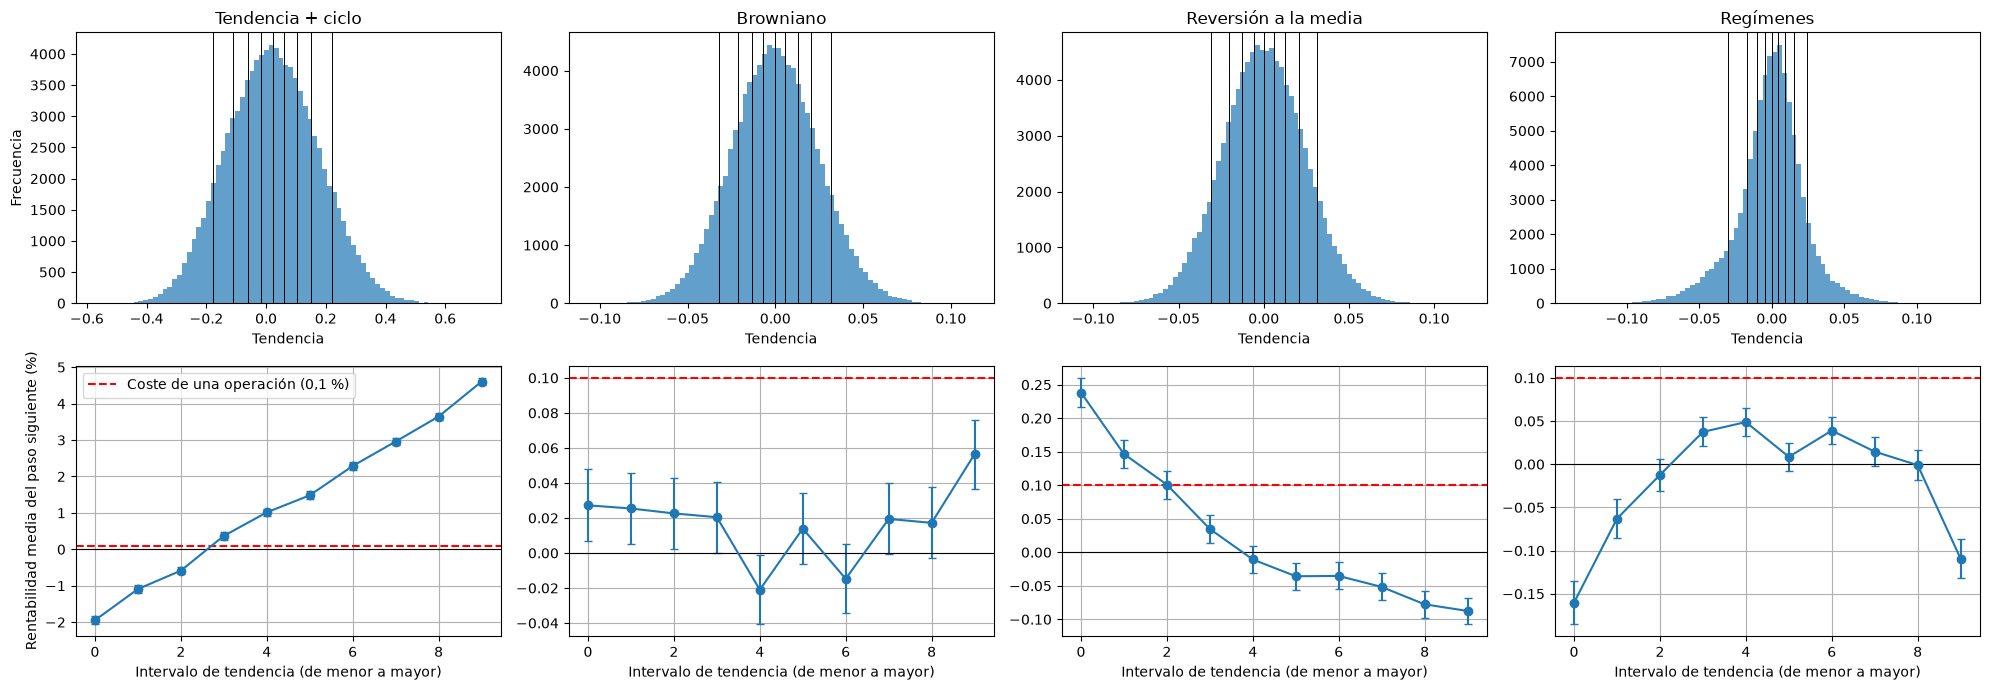

In [17]:
fig, axs = plt.subplots(2, len(GENERADORES), figsize=(20, 7))
for col, (gen, generador) in enumerate(GENERADORES.items()):
    disc = TrendDiscretizer.ajustar(generador, 10)
    tendencias, siguientes = [], []
    for precios in crear_series(generador, 200, N_STEPS, SEED_AJUSTE + 1):
        env = SimpleTradingEnv(precios)
        obs, _ = env.reset()
        terminated = False
        while not terminated:
            tendencia = obs[0]
            obs, _, terminated, _, _ = env.step(1)
            tendencias.append(tendencia)
            siguientes.append(precios[env.current_step] / precios[env.current_step - 1] - 1)
    tendencias, siguientes = np.array(tendencias), np.array(siguientes)
    intervalo = np.searchsorted(disc.limites, tendencias, side="right")

    axs[0, col].hist(tendencias, bins=80, color="tab:blue", alpha=0.7)
    for limite in disc.limites:
        axs[0, col].axvline(limite, color="black", linewidth=0.7)
    axs[0, col].set_title(gen)
    axs[0, col].set_xlabel("Tendencia")

    medias = np.array([siguientes[intervalo == i].mean() for i in range(disc.n_bins)])
    errores = np.array([siguientes[intervalo == i].std() / np.sqrt((intervalo == i).sum()) for i in range(disc.n_bins)])
    axs[1, col].errorbar(range(disc.n_bins), 100 * medias, yerr=100 * errores, fmt="o-", color="tab:blue", capsize=3)
    axs[1, col].axhline(0, color="black", linewidth=0.8)
    axs[1, col].axhline(0.1, color="red", linestyle="--", label="Coste de una operación (0,1 %)")
    axs[1, col].set_xlabel("Intervalo de tendencia (de menor a mayor)")
    axs[1, col].grid(True)
    if col == 0:
        axs[0, col].set_ylabel("Frecuencia")
        axs[1, col].set_ylabel("Rentabilidad media del paso siguiente (%)")
        axs[1, col].legend(loc="best")
plt.tight_layout()
plt.show()

## 3. El agente Sarsa

Sarsa aprende la función de valor de acción $Q(s,a)$ con la regla (diapositiva 29 del tema de TD):

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,\big[R_{t+1} + \gamma\, Q(S_{t+1},A_{t+1}) - Q(S_t,A_t)\big]$$

donde $A_{t+1}$ se elige con la **misma política $\epsilon$-greedy** que se usa para interactuar con el entorno (*on-policy*). En el estado terminal $Q(\text{terminal},\cdot)=0$, así que en la última transición el objetivo es simplemente $R_{t+1}$.

**Decisiones de diseño**

- **Acciones válidas.** Con `posición = 0`, vender no tiene efecto (equivale a mantener); con `posición = 1`, comprar tampoco (equivale a mantener). Como $A(s)$ puede depender del estado, en cada posición solo se consideran las 2 acciones con efecto distinto: `{mantener, comprar}` sin activo y `{mantener, vender}` con activo. Así no se reparten los datos entre acciones redundantes. (Se puede desactivar con `mascara=False` y se compara en las ablaciones.)
- **Empates.** Al explorar o entrenar los empates de $Q$ se rompen al azar; al *evaluar* se desempata a favor de *mantener* (Q inicial = 0, así que un agente sin entrenar no opera).
- **Decaimiento de $\epsilon$.** Geométrico desde `eps_inicial` hasta `eps_final`, alcanzado en la fracción `eps_frac` del entrenamiento. Es la forma de compaginar exploración (al principio) y explotación (al final).
- **Decaimiento de $\alpha$** (opcional). Geométrico desde `alpha` hasta `alpha_final`. Con $\alpha$ constante los valores oscilan alrededor del valor verdadero; reducir $\alpha$ amortigua ese ruido (condiciones de convergencia $\sum\alpha=\infty$, $\sum\alpha^2<\infty$).
- La clase base `AgenteTabular` contiene todo lo que no depende del algoritmo (tabla $Q$, política $\epsilon$-greedy, calendarios de $\alpha$ y $\epsilon$) y `AgenteSarsa` solo define cómo se actualiza.

In [18]:
class AgenteTabular:
    """Tabla Q, política ε-greedy y calendarios de α y ε. Las subclases definen `entrenar_episodio`."""

    # Acciones con efecto distinto en cada posición, con 'mantener' (1) primero para desempatar en evaluación
    ACCIONES = {0: (1, 2), 1: (1, 0)}

    def __init__(self, disc, alpha=0.1, alpha_final=None, gamma=0.9,
                 eps_inicial=1.0, eps_final=0.01, eps_frac=0.6, mascara=True, seed=0):
        self.disc = disc
        self.alpha0, self.alpha_final = alpha, alpha_final
        self.gamma = gamma
        self.eps_inicial, self.eps_final, self.eps_frac = eps_inicial, eps_final, eps_frac
        self.rng = random.Random(seed)
        todas = (1, 0, 2)
        self.validas = self.ACCIONES if mascara else {0: todas, 1: todas}
        self.Q = [[0.0] * 3 for _ in range(disc.n_estados)]
        self.visitas = [[0] * 3 for _ in range(disc.n_estados)]
        self.alpha, self.eps = alpha, eps_inicial

    def fijar_episodio(self, ep, n_episodios):
        """Calendario de ε y α para el episodio `ep` (0, 1, ..., n_episodios - 1)."""
        tramo = max(1.0, self.eps_frac * n_episodios)
        self.eps = max(self.eps_final, self.eps_inicial * (self.eps_final / self.eps_inicial) ** (ep / tramo))
        if self.alpha_final is not None:
            self.alpha = self.alpha0 * (self.alpha_final / self.alpha0) ** (ep / max(1, n_episodios - 1))

    def accion_greedy(self, s, aleatorio=True):
        acciones, q = self.validas[s & 1], self.Q[s]
        mejor = max(q[a] for a in acciones)
        empatadas = [a for a in acciones if q[a] == mejor]
        return self.rng.choice(empatadas) if aleatorio and len(empatadas) > 1 else empatadas[0]

    def elegir_accion(self, s):
        """Política ε-greedy respecto a la Q actual."""
        if self.rng.random() < self.eps:
            return self.rng.choice(self.validas[s & 1])
        return self.accion_greedy(s)

    def politica(self, obs):
        """Política greedy determinista (ε = 0), la que se usa para evaluar."""
        return self.accion_greedy(self.disc(obs), aleatorio=False)

    @property
    def tabla_q(self):
        """Q con forma (intervalo de tendencia, posición, acción)."""
        return np.array(self.Q).reshape(self.disc.n_bins, 2, 3)

    def entrenar_episodio(self, env):
        raise NotImplementedError


class AgenteSarsa(AgenteTabular):
    """Sarsa: control TD on-policy."""

    def actualizar(self, s, a, r, s2, a2, terminal):
        """Q(S,A) <- Q(S,A) + α [R + γ Q(S',A') - Q(S,A)], con Q(terminal, ·) = 0."""
        objetivo = r if terminal else r + self.gamma * self.Q[s2][a2]
        self.Q[s][a] += self.alpha * (objetivo - self.Q[s][a])

    def entrenar_episodio(self, env):
        obs, _ = env.reset()
        s = self.disc(obs)
        a = self.elegir_accion(s)                      # A elegida desde S con la política ε-greedy
        retorno, terminated, truncated = 0.0, False, False

        while not (terminated or truncated):
            obs, r, terminated, truncated, _ = env.step(a)
            s2 = self.disc(obs)
            a2 = None if terminated else self.elegir_accion(s2)   # A' desde S' (misma política)
            self.actualizar(s, a, r, s2, a2, terminated)
            self.visitas[s][a] += 1
            retorno += r
            s, a = s2, a2

        return retorno, env.balance

### Entrenamiento

En **cada episodio** se genera una serie de precios nueva con el mismo generador (el agente ve muchos "mercados" distintos del mismo tipo y no memoriza una serie). Cada cierto número de episodios se evalúa la política greedy sobre un conjunto fijo de series de **validación**, lo que da la curva de aprendizaje y permite medir la velocidad de convergencia. La fila del episodio 0 corresponde al agente sin entrenar.

In [19]:
def entrenar_agente(agente, generador, n_episodios, semilla=0, series_val=None, cada=100, n_steps=N_STEPS,
                    env_cls=SimpleTradingEnv):
    np.random.seed(semilla)       # semilla de las series de entrenamiento (distinta de la de val/test)
    hist = {"ret_train": [], "bal_train": [], "ep_val": [], "val_logret": [], "val_balance": [], "t_train": 0.0}

    def validar(ep):
        res = evaluar(agente.politica, series_val, env_cls)
        hist["ep_val"].append(ep)
        hist["val_logret"].append(np.log(res["final"] / CAPITAL_INICIAL).mean())
        hist["val_balance"].append(res["final"].mean())

    if series_val is not None:
        validar(0)

    for ep in range(n_episodios):
        agente.fijar_episodio(ep, n_episodios)
        env = env_cls(generador(n_steps))
        t0 = time.perf_counter()
        retorno, balance = agente.entrenar_episodio(env)
        hist["t_train"] += time.perf_counter() - t0
        hist["ret_train"].append(retorno)
        hist["bal_train"].append(balance)
        if series_val is not None and ((ep + 1) % cada == 0 or ep + 1 == n_episodios):
            validar(ep + 1)

    return hist


def episodios_convergencia(ep_val, curva, frac=0.9, ventana=3):
    """Primer episodio en el que la curva (suavizada) alcanza `frac` de la mejora total respecto al inicio."""
    curva = np.asarray(curva, dtype=float)
    suave = np.convolve(curva, np.ones(ventana) / ventana, mode="valid")
    ep = np.asarray(ep_val)[ventana - 1:]
    final = curva[-max(3, len(curva) // 5):].mean()
    inicio = curva[0]
    if final <= inicio:
        return np.nan               # no hay mejora respecto al agente sin entrenar
    return ep[np.argmax(suave >= inicio + frac * (final - inicio))]

## 4. Ajuste de hiperparámetros

Se ajustan **por separado para cada generador de precios** (cada tipo de mercado tiene una estructura distinta) y **solo con las series de validación**; las de test no se tocan hasta la evaluación final.

**Protocolo**

1. *Búsqueda aleatoria* de `N_CONFIGS` configuraciones (las mismas para los cuatro generadores) con un entrenamiento corto de `N_EP_BUSQUEDA` episodios y varias semillas. Se explora $\alpha$ (escala logarítmica, con y sin decaimiento), $\gamma$, el número de intervalos de la discretización y el calendario de $\epsilon$ (valor final y fracción del entrenamiento que dura el decaimiento).
2. *Re-evaluación* de las `TOP_K` mejores configuraciones de cada generador con el entrenamiento completo (`N_EPISODES` episodios) y semillas nuevas, para no quedarse con una configuración que ganó por azar en un entrenamiento corto.

El criterio es el **retorno logarítmico medio** del balance final de la política *greedy* en validación, $\overline{\ln(B_T/B_0)}$. Es el criterio natural para capital que se reinvierte y es mucho más estable que el balance medio, que en series muy volátiles lo dominan unas pocas series con precios extremos.

La búsqueda se ejecuta en paralelo (cada entrenamiento tiene su propia semilla, así que el resultado no depende del reparto entre procesos). Si no se quiere repetir, poner `RUN_TUNING = False` y se usarán los mejores hiperparámetros ya obtenidos (`MEJORES_PARAMS_GUARDADOS`, más abajo).

In [20]:
RUN_TUNING = True

N_CONFIGS = 40
N_EP_BUSQUEDA = 1000
SEMILLAS_BUSQUEDA = (100, 101)
TOP_K = 3
SEMILLAS_REEVAL = (200, 201, 202)
N_EPISODES = 3000            # entrenamiento completo (se justifica con las curvas de aprendizaje)


def tarea_sarsa(gen, params, n_episodios, semilla, cada=None):
    """Entrena un agente Sarsa (descritos por `params`) en el generador `gen` y devuelve agente e historial."""
    generador = GENERADORES[gen]
    params = dict(params)
    disc = TrendDiscretizer.ajustar(generador, params.pop("n_bins"))
    agente = AgenteSarsa(disc, seed=semilla, **params)
    series_val = crear_series(generador, N_VAL, N_STEPS, SEED_VAL)
    hist = entrenar_agente(agente, generador, n_episodios, semilla, series_val, cada or n_episodios)
    return {"gen": gen, "semilla": semilla, "agente": agente, "hist": hist}


def muestrear_configs(n, seed=0):
    rng = random.Random(seed)
    configs = []
    for i in range(n):
        alpha = float(round(10 ** rng.uniform(np.log10(0.002), np.log10(0.3)), 4))
        factor = rng.choice([1.0, 0.1, 0.01])        # α_final = factor · α (1.0 = α constante)
        configs.append({"id": i, "alpha": alpha, "factor_alpha": factor,
                        "alpha_final": None if factor == 1.0 else round(alpha * factor, 6),
                        "gamma": rng.choice([0.0, 0.5, 0.9, 0.99]),
                        "n_bins": rng.choice([5, 9, 15, 25]),
                        "eps_final": rng.choice([0.01, 0.05, 0.1]),
                        "eps_frac": rng.choice([0.3, 0.6, 0.9])})
    return configs


CLAVES_AGENTE = ("alpha", "alpha_final", "gamma", "n_bins", "eps_final", "eps_frac")


def params_agente(config):
    return {k: config[k] for k in CLAVES_AGENTE}


if RUN_TUNING:
    configs = muestrear_configs(N_CONFIGS)
    meta = [(gen, c, s) for gen in GENERADORES for c in configs for s in SEMILLAS_BUSQUEDA]
    tareas = [dict(gen=gen, params=params_agente(c), n_episodios=N_EP_BUSQUEDA, semilla=s) for gen, c, s in meta]
    t0 = time.perf_counter()
    salidas = ejecutar(tarea_sarsa, tareas)
    print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s ({N_JOBS if HAY_JOBLIB else 1} procesos)")

    busqueda = pd.DataFrame([{"gen": gen, "config": c["id"], "semilla": s,
                              **{k: c[k] for k in CLAVES_AGENTE + ("factor_alpha",)},
                              "score": o["hist"]["val_logret"][-1]}
                             for (gen, c, s), o in zip(meta, salidas)])
    # puntuación de cada configuración: media sobre las semillas
    ranking = busqueda.groupby(["gen", "config"]).score.mean().rename("score").reset_index()

320 entrenamientos en 418 s (15 procesos)


### Sensibilidad a los hiperparámetros

Puntuación media (retorno logarítmico en validación) de las configuraciones de la búsqueda aleatoria agrupadas por el valor de cada hiperparámetro. Cada fila es un generador (con su propia escala vertical); la columna $\alpha$ agrupa los valores muestreados en cuartiles.

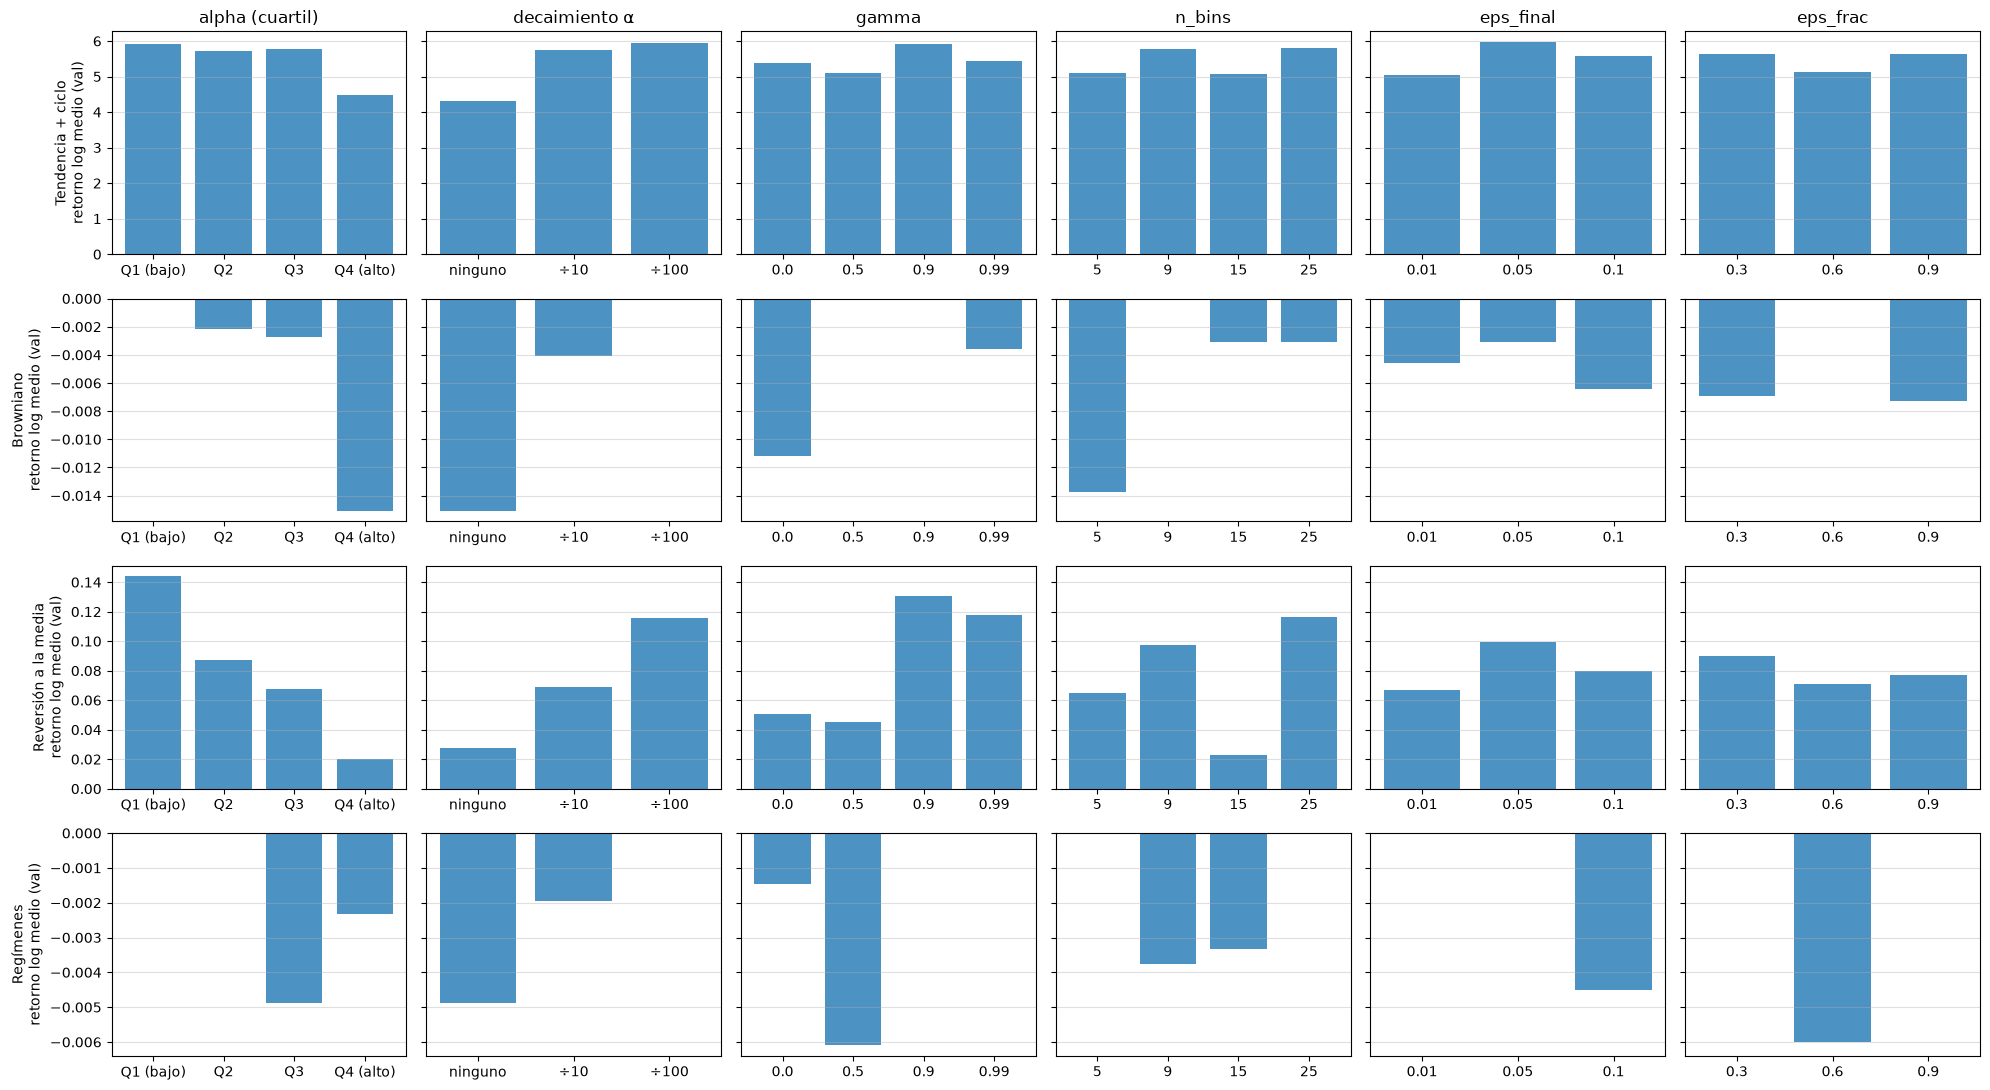

gen
Browniano               95.0
Regímenes               97.5
Reversión a la media    33.8
Tendencia + ciclo        1.2


In [21]:
if RUN_TUNING:
    busqueda["alpha (cuartil)"] = pd.qcut(busqueda.alpha, 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
    busqueda["decaimiento α"] = busqueda.factor_alpha.map({1.0: "ninguno", 0.1: "÷10", 0.01: "÷100"})
    columnas = ["alpha (cuartil)", "decaimiento α", "gamma", "n_bins", "eps_final", "eps_frac"]

    fig, axs = plt.subplots(len(GENERADORES), len(columnas), figsize=(20, 11), sharey="row")
    for i, gen in enumerate(GENERADORES):
        d = busqueda[busqueda.gen == gen]
        for j, col in enumerate(columnas):
            medias = d.groupby(col, observed=True).score.mean()
            axs[i, j].bar(range(len(medias)), medias.values, color="tab:blue", alpha=0.8)
            axs[i, j].set_xticks(range(len(medias)))
            axs[i, j].set_xticklabels([str(x) for x in medias.index])
            axs[i, j].grid(True, axis="y", alpha=0.4)
            if i == 0:
                axs[i, j].set_title(col)
            if j == 0:
                axs[i, j].set_ylabel(f"{gen}\nretorno log medio (val)")
    plt.tight_layout()
    plt.show()

    sin_operar = busqueda.groupby("gen").score.apply(lambda s: 100 * (s == 0).mean()).rename("% entrenamientos sin operar (score = 0)")
    print(sin_operar.round(1).to_string())

### Re-evaluación de los mejores candidatos

Las `TOP_K` mejores configuraciones de cada generador se vuelven a entrenar con `N_EPISODES` episodios y semillas nuevas. Se queda la de mayor puntuación media en validación.

In [22]:
# Mejores hiperparámetros obtenidos en una ejecución de este notebook (se usan si RUN_TUNING = False)
MEJORES_PARAMS_GUARDADOS = {
    "Tendencia + ciclo": {"alpha": 0.014, "alpha_final": 0.0014, "gamma": 0.0, "n_bins": 5, "eps_final": 0.1, "eps_frac": 0.3},
    "Browniano": {"alpha": 0.0251, "alpha_final": 0.00251, "gamma": 0.5, "n_bins": 5, "eps_final": 0.1, "eps_frac": 0.6},
    "Reversión a la media": {"alpha": 0.007, "alpha_final": 7e-05, "gamma": 0.0, "n_bins": 25, "eps_final": 0.1, "eps_frac": 0.3},
    "Regímenes": {"alpha": 0.0152, "alpha_final": 0.00152, "gamma": 0.99, "n_bins": 15, "eps_final": 0.1, "eps_frac": 0.3},
}

if RUN_TUNING:
    mejores = (ranking.sort_values(["gen", "score"], ascending=[True, False], kind="stable")
                      .groupby("gen").head(TOP_K))
    meta = [(r.gen, r.config, s) for r in mejores.itertuples() for s in SEMILLAS_REEVAL]
    tareas = [dict(gen=gen, params=params_agente(configs[c]), n_episodios=N_EPISODES, semilla=s) for gen, c, s in meta]
    t0 = time.perf_counter()
    salidas = ejecutar(tarea_sarsa, tareas)
    print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

    reeval = pd.DataFrame([{"gen": gen, "config": c, "semilla": s, "score": o["hist"]["val_logret"][-1]}
                           for (gen, c, s), o in zip(meta, salidas)])
    reeval = reeval.groupby(["gen", "config"]).score.mean().reset_index()
    reeval = reeval.merge(pd.DataFrame(configs), left_on="config", right_on="id")
    reeval = reeval[["gen", "config", "score"] + list(CLAVES_AGENTE)]
    display(reeval.sort_values(["gen", "score"], ascending=[True, False]).reset_index(drop=True))

    elegida = reeval.sort_values("score", ascending=False, kind="stable").groupby("gen").head(1)
    MEJORES_PARAMS = {r.gen: params_agente(configs[r.config]) for r in elegida.itertuples()}
else:
    MEJORES_PARAMS = MEJORES_PARAMS_GUARDADOS

for gen, p in MEJORES_PARAMS.items():
    print(f"{gen:22s}", p)

36 entrenamientos en 129 s


,gen,config,score,alpha,alpha_final,gamma,n_bins,eps_final,eps_frac
0,Browniano,2,0.000000,0.0251,0.002510,0.50,5,0.10,0.6
1,Browniano,3,0.000000,0.2814,0.002814,0.50,15,0.01,0.9
2,Browniano,0,-0.041794,0.1376,0.013760,0.00,15,0.10,0.6
3,Regímenes,1,0.000000,0.0152,0.001520,0.99,15,0.10,0.3
4,Regímenes,2,0.000000,0.0251,0.002510,0.50,5,0.10,0.6
5,Regímenes,0,-0.043968,0.1376,0.013760,0.00,15,0.10,0.6
6,Reversión a la media,33,0.193932,0.0070,0.000070,0.00,25,0.10,0.3
7,Reversión a la media,4,0.192519,0.0029,0.000029,0.90,25,0.10,0.3
8,Reversión a la media,23,0.162529,0.0051,0.000051,0.00,25,0.01,0.6
9,Tendencia + ciclo,36,6.373434,0.0140,0.001400,0.00,5,0.10,0.3


Tendencia + ciclo      {'alpha': 0.014, 'alpha_final': 0.0014, 'gamma': 0.0, 'n_bins': 5, 'eps_final': 0.1, 'eps_frac': 0.3}
Reversión a la media   {'alpha': 0.007, 'alpha_final': 7e-05, 'gamma': 0.0, 'n_bins': 25, 'eps_final': 0.1, 'eps_frac': 0.3}
Browniano              {'alpha': 0.0251, 'alpha_final': 0.00251, 'gamma': 0.5, 'n_bins': 5, 'eps_final': 0.1, 'eps_frac': 0.6}
Regímenes              {'alpha': 0.0152, 'alpha_final': 0.00152, 'gamma': 0.99, 'n_bins': 15, 'eps_final': 0.1, 'eps_frac': 0.3}


## 5. Resultados finales

Con los mejores hiperparámetros de cada generador se entrenan **5 agentes Sarsa independientes** (semillas distintas) durante `N_EPISODES` episodios, cada episodio con una serie de precios nueva. Los agentes se evalúan con la política *greedy* sobre **200 series de test** nuevas (las mismas para todos los métodos, de modo que las comparaciones son pareadas) y los resultados se promedian sobre las 5 semillas.

In [23]:
SEMILLAS_FINAL = (0, 1, 2, 3, 4)

tareas = [dict(gen=gen, params=MEJORES_PARAMS[gen], n_episodios=N_EPISODES, semilla=s, cada=100)
          for gen in GENERADORES for s in SEMILLAS_FINAL]
t0 = time.perf_counter()
salidas = ejecutar(tarea_sarsa, tareas)
print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

FINALES = {gen: [o for o in salidas if o["gen"] == gen] for gen in GENERADORES}
SERIES_VAL = {gen: crear_series(g, N_VAL, N_STEPS, SEED_VAL) for gen, g in GENERADORES.items()}
SERIES_TEST = {gen: crear_series(g, N_TEST, N_STEPS, SEED_TEST) for gen, g in GENERADORES.items()}

20 entrenamientos en 137 s


### Curvas de aprendizaje y velocidad de convergencia

**Izquierda:** retorno logarítmico medio de la política *greedy* sobre las series de validación a lo largo del entrenamiento (media ± desviación típica entre las 5 semillas), junto a los *baselines*. Sirve para decidir cuántos episodios hacen falta. **Derecha:** rendimiento *durante* el entrenamiento, es decir, con la política $\epsilon$-greedy que realmente se está ejecutando (media móvil de 100 episodios de la recompensa acumulada), y el calendario de $\epsilon$.

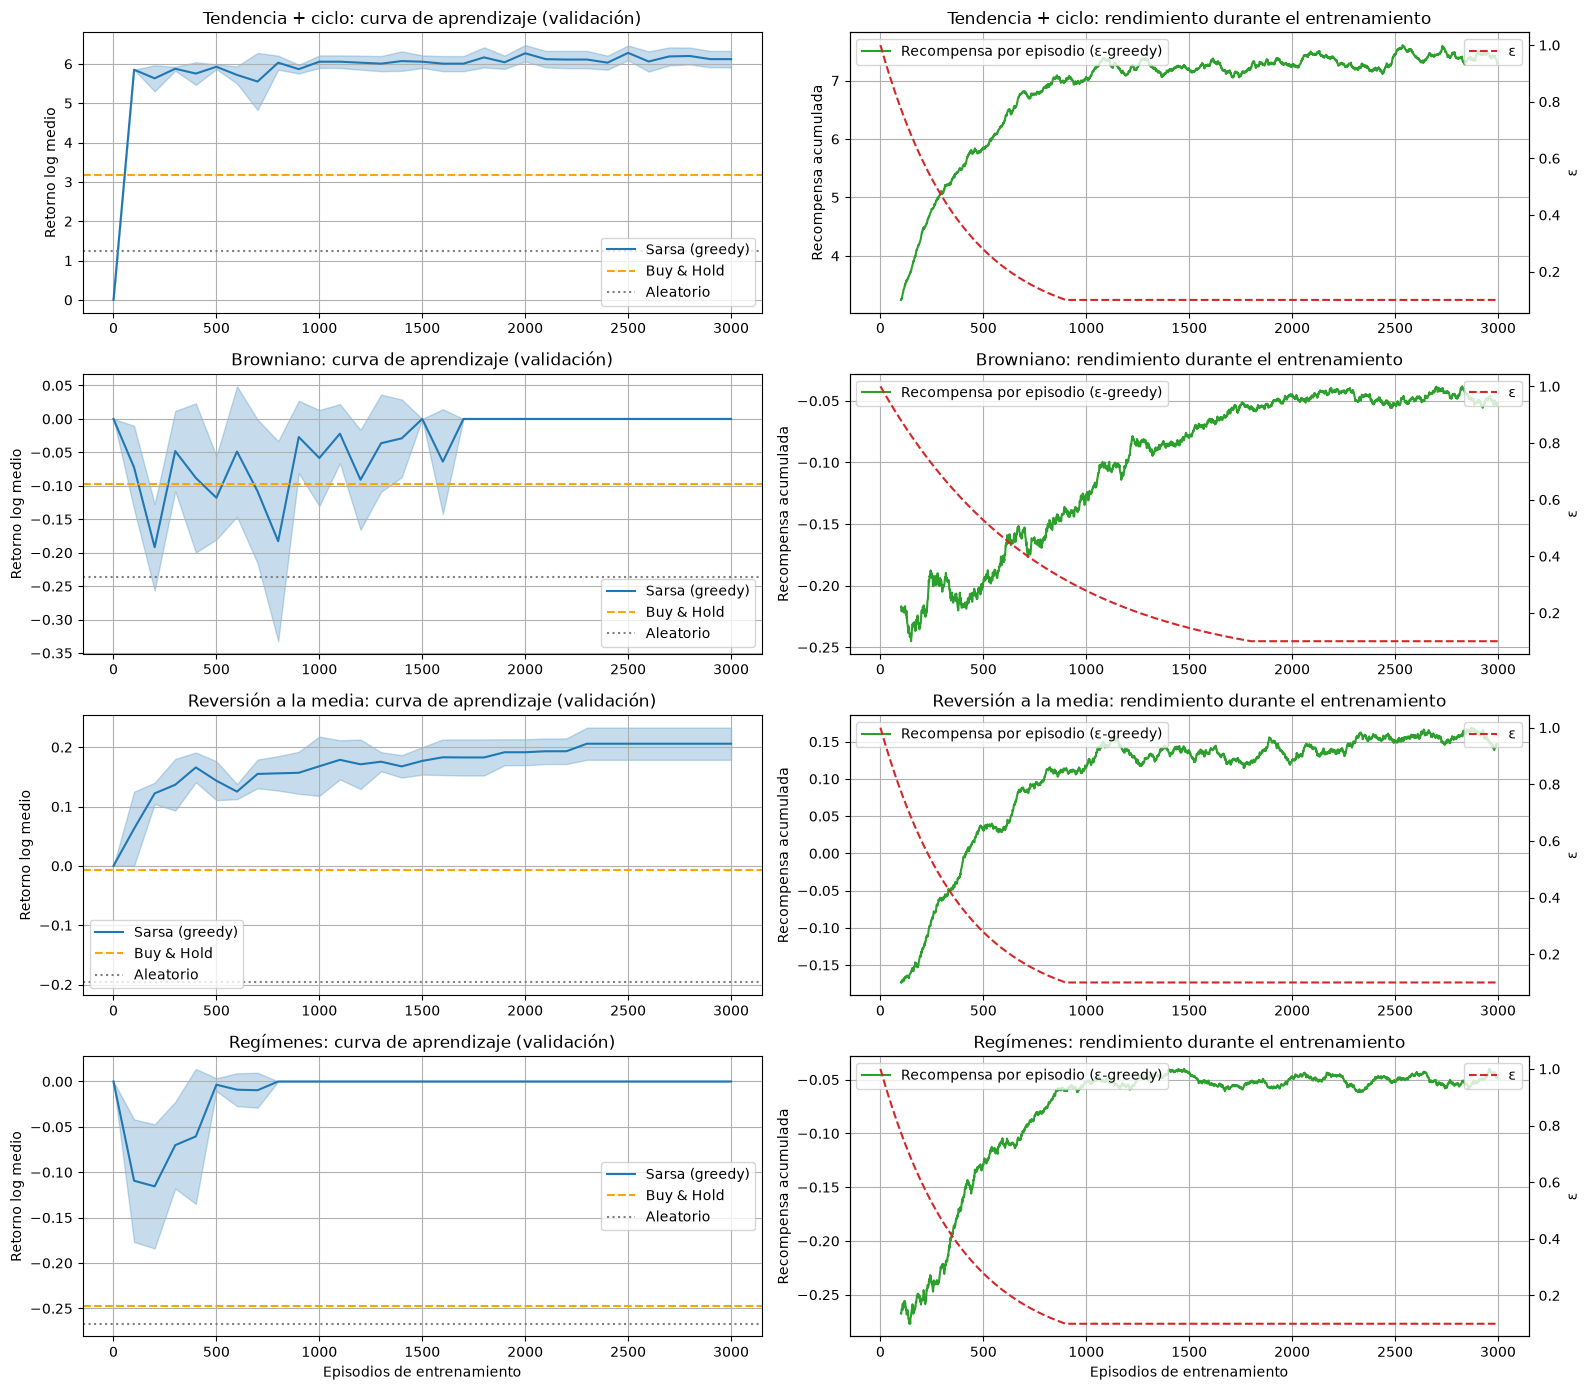

In [24]:
def curva_baseline(politica, gen):
    res = evaluar(politica, SERIES_VAL[gen])
    return np.log(res["final"] / CAPITAL_INICIAL).mean()


fig, axs = plt.subplots(len(GENERADORES), 2, figsize=(16, 14))
for fila, gen in enumerate(GENERADORES):
    hist = [o["hist"] for o in FINALES[gen]]
    ep = hist[0]["ep_val"]
    curvas = np.array([h["val_logret"] for h in hist])
    ax = axs[fila, 0]
    ax.plot(ep, curvas.mean(0), color="tab:blue", label="Sarsa (greedy)")
    ax.fill_between(ep, curvas.mean(0) - curvas.std(0), curvas.mean(0) + curvas.std(0), color="tab:blue", alpha=0.25)
    ax.axhline(curva_baseline(comprar_y_mantener, gen), color="orange", linestyle="--", label="Buy & Hold")
    ax.axhline(curva_baseline(PoliticaAleatoria(0), gen), color="gray", linestyle=":", label="Aleatorio")
    ax.set_title(f"{gen}: curva de aprendizaje (validación)")
    ax.set_ylabel("Retorno log medio")
    ax.grid(True)
    ax.legend(loc="best")

    ax = axs[fila, 1]
    retornos = np.array([h["ret_train"] for h in hist]).mean(0)
    suave = np.convolve(retornos, np.ones(100) / 100, mode="valid")
    ax.plot(np.arange(100, len(retornos) + 1), suave, color="tab:green", label="Recompensa por episodio (ε-greedy)")
    ax.set_title(f"{gen}: rendimiento durante el entrenamiento")
    ax.set_ylabel("Recompensa acumulada")
    ax.grid(True)
    ax2 = ax.twinx()
    agente = FINALES[gen][0]["agente"]
    epsilons = []
    for e in range(N_EPISODES):
        agente.fijar_episodio(e, N_EPISODES)
        epsilons.append(agente.eps)
    ax2.plot(epsilons, color="tab:red", linestyle="--", label="ε")
    ax2.set_ylabel("ε")
    ax.legend(loc="upper left")
    ax2.legend(loc="upper right")
    if fila == len(GENERADORES) - 1:
        axs[fila, 0].set_xlabel("Episodios de entrenamiento")
        ax.set_xlabel("Episodios de entrenamiento")
plt.tight_layout()
plt.show()

### Comparación con los *baselines* sobre las series de test

Columnas: balance final medio y mediano ($B_0 = 1000$), retorno logarítmico medio, diferencia media respecto a *buy & hold* en las mismas series (con su error estándar), porcentaje de series en las que se supera a *buy & hold*, número medio de operaciones por episodio, episodios hasta alcanzar el 90 % de la mejora total en validación y tiempo de entrenamiento (CPU). Para Sarsa, los valores son la media sobre las 5 semillas y, entre paréntesis, la desviación típica entre semillas del balance medio. Un "—" en la convergencia indica que el agente no mejora respecto a no operar y por tanto no hay convergencia que medir.

In [25]:
RESULTADOS = {}                       # (generador, algoritmo) -> métricas; Q-Learning puede añadir sus filas aquí
ALGORITMOS = ["Aleatorio", "Buy & Hold", "Sarsa"]

for gen in GENERADORES:
    bh = evaluar(comprar_y_mantener, SERIES_TEST[gen])
    RESULTADOS[(gen, "Aleatorio")] = resumen(evaluar(PoliticaAleatoria(0), SERIES_TEST[gen]), bh)
    RESULTADOS[(gen, "Buy & Hold")] = resumen(bh, bh)

    por_semilla = [resumen(evaluar(o["agente"].politica, SERIES_TEST[gen]), bh) for o in FINALES[gen]]
    fila = {k: np.mean([r[k] for r in por_semilla]) for k in por_semilla[0]}
    fila["Desv. balance entre semillas"] = np.std([r["Balance medio ($)"] for r in por_semilla])
    conv = np.array([episodios_convergencia(o["hist"]["ep_val"], o["hist"]["val_logret"]) for o in FINALES[gen]])
    fila["Episodios hasta converger"] = np.nan if np.all(np.isnan(conv)) else np.nanmean(conv)
    fila["Tiempo entrenamiento (s)"] = np.mean([o["hist"]["t_train"] for o in FINALES[gen]])
    RESULTADOS[(gen, "Sarsa")] = fila


def tabla_resultados(resultados):
    filas = []
    for (gen, alg), r in resultados.items():
        balance = f"{r['Balance medio ($)']:,.0f}"
        if "Desv. balance entre semillas" in r:
            balance += f" (±{r['Desv. balance entre semillas']:,.0f})"
        filas.append({
            "Generador": gen, "Algoritmo": alg, "Balance medio ($)": balance,
            "Mediana ($)": f"{r['Mediana ($)']:,.0f}",
            "Retorno log medio": f"{r['Retorno log medio']:.3f}",
            "Δ vs B&H ($)": f"{r['Δ vs B&H ($)']:+,.0f} ± {r['EE Δ vs B&H']:,.0f}" if alg != "Buy & Hold" else "—",
            "% series > B&H": f"{r['% series > B&H']:.0f}" if alg != "Buy & Hold" else "—",
            "Operaciones": f"{r['Operaciones']:.1f}",
            "Episodios conv.": ("—" if np.isnan(r.get("Episodios hasta converger", np.nan)) else f"{r['Episodios hasta converger']:.0f}")
                               if "Episodios hasta converger" in r else "",
            "Tiempo entren. (s)": f"{r['Tiempo entrenamiento (s)']:.0f}" if "Tiempo entrenamiento (s)" in r else "",
        })
    return pd.DataFrame(filas).set_index(["Generador", "Algoritmo"])


display(tabla_resultados(RESULTADOS))

Balance medio ($) Mediana ($)  \
Generador            Algoritmo                                      
Tendencia + ciclo    Aleatorio                 14,494       4,072   
                     Buy & Hold               323,278      35,269   
                     Sarsa       3,679,487 (±764,909)     590,177   
Browniano            Aleatorio                    860         810   
                     Buy & Hold                 1,077         984   
                     Sarsa                 1,000 (±0)       1,000   
Reversión a la media Aleatorio                    898         887   
                     Buy & Hold                   998         998   
                     Sarsa                1,260 (±49)       1,243   
Regímenes            Aleatorio                    795         775   
                     Buy & Hold                   883         818   
                     Sarsa                 1,000 (±0)       1,000   

                                Retorno log medio          Δ vs B&H ($)  \
Generador            Algoritmo                                            
Tendencia + ciclo    Aleatorio              1.428     -308,784 ± 79,709   
                     Buy & Hold             3.459                     —   
                     Sarsa                  6.321  +3,356,209 ± 906,795   
Browniano            Aleatorio             -0.201             -217 ± 24   
                     Buy & Hold            -0.036                     —   
                     Sarsa                  0.000              -77 ± 36   
Reversión a la media Aleatorio             -0.135             -100 ± 15   
                     Buy & Hold            -0.005                     —   
                     Sarsa                  0.217             +262 ± 15   
Regímenes            Aleatorio             -0.277              -88 ± 21   
                     Buy & Hold            -0.226                     —   
                     Sarsa                  0.000             +117 ± 28   

                                % series > B&H Operaciones Episodios conv.  \
Generador            Algoritmo                                               
Tendencia + ciclo    Aleatorio              15       166.0                   
                     Buy & Hold              —         1.0                   
                     Sarsa                  96        46.8             320   
Browniano            Aleatorio              30       166.0                   
                     Buy & Hold              —         1.0                   
                     Sarsa                  51         0.0               —   
Reversión a la media Aleatorio              26       166.0                   
                     Buy & Hold              —         1.0                   
                     Sarsa                  90        25.3            1420   
Regímenes            Aleatorio              42       166.0                   
                     Buy & Hold              —         1.0                   
                     Sarsa                  67         0.0               —   

                                Tiempo entren. (s)  
Generador            Algoritmo                      
Tendencia + ciclo    Aleatorio                      
                     Buy & Hold                     
                     Sarsa                      45  
Browniano            Aleatorio                      
                     Buy & Hold                     
                     Sarsa                      44  
Reversión a la media Aleatorio                      
                     Buy & Hold                     
                     Sarsa                      45  
Regímenes            Aleatorio                      
                     Buy & Hold                     
                     Sarsa                      23

### Un episodio de test con cada generador

Mismo formato que el agente aleatorio de arriba: el precio se colorea en verde cuando el agente posee el activo y en rojo cuando no lo posee. Abajo, evolución del balance frente a *buy & hold* y al agente aleatorio.

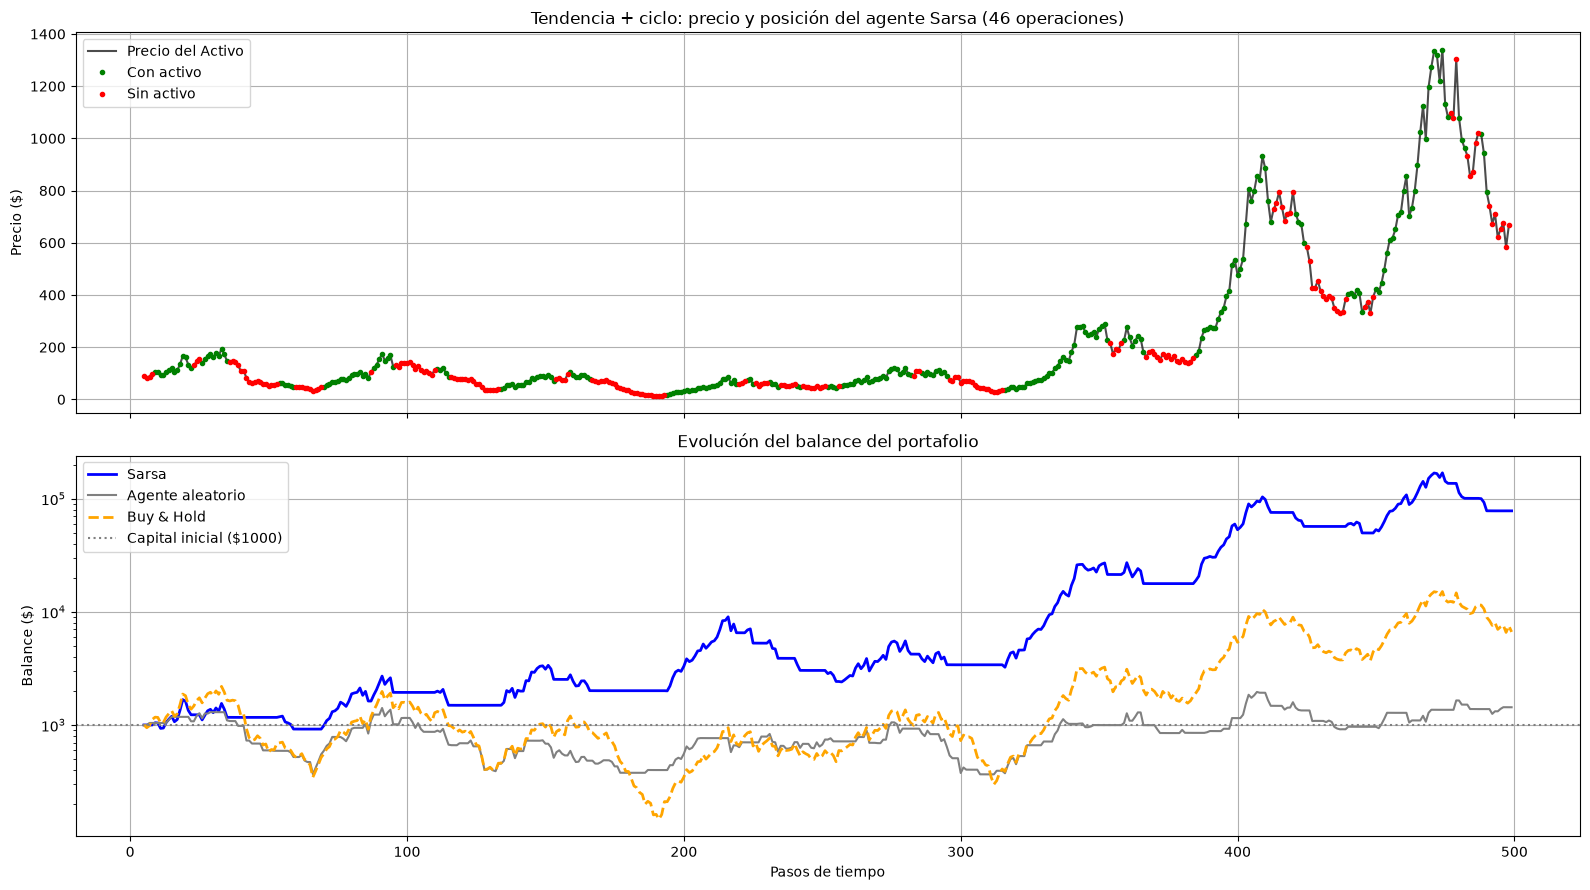

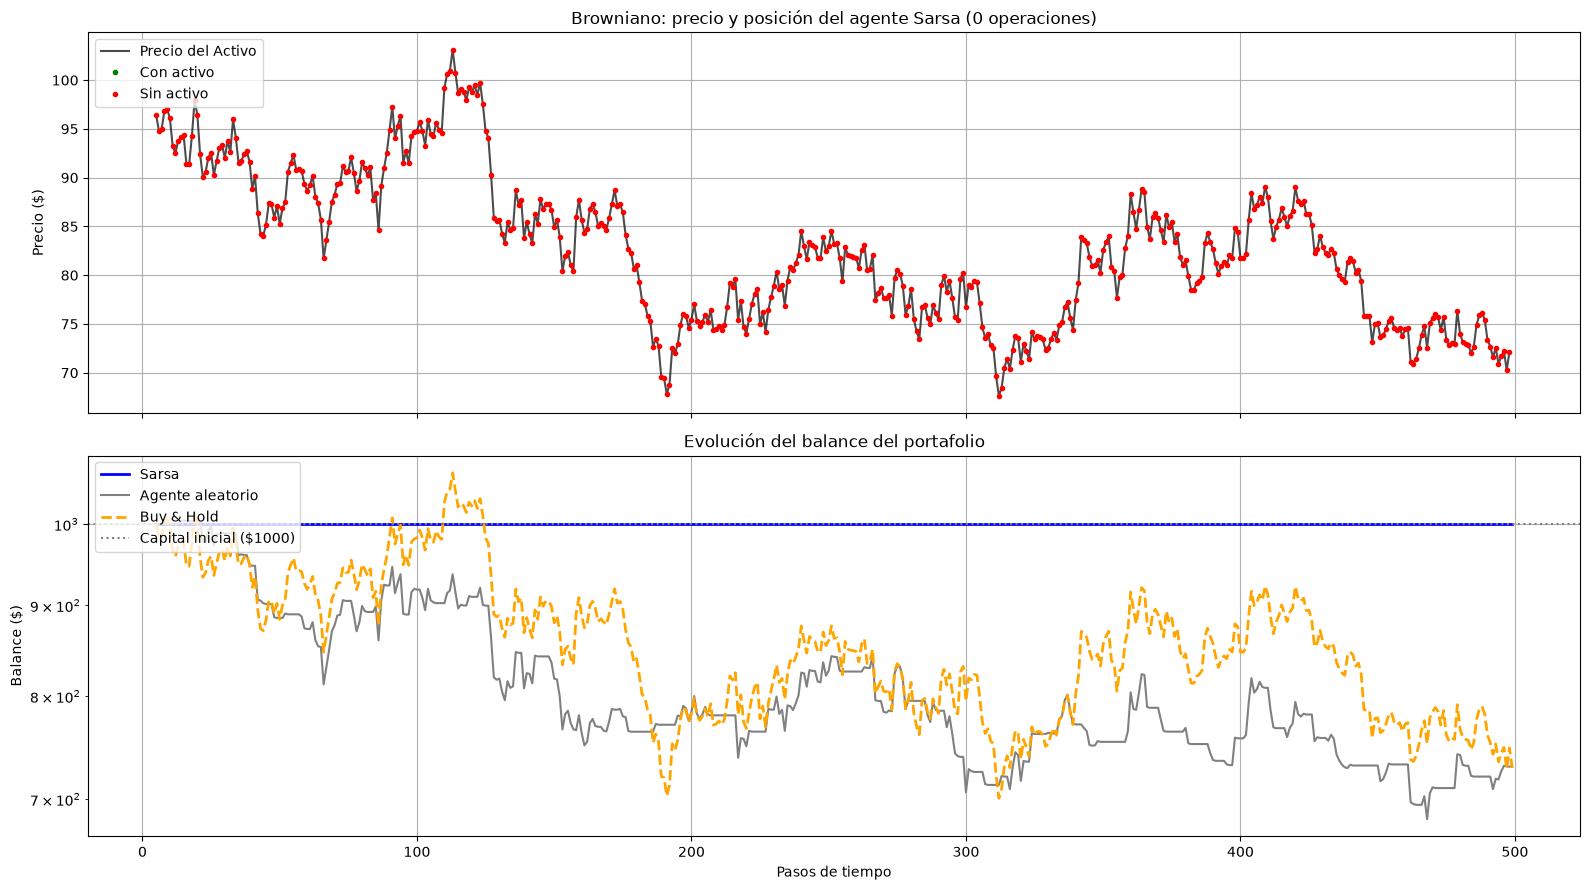

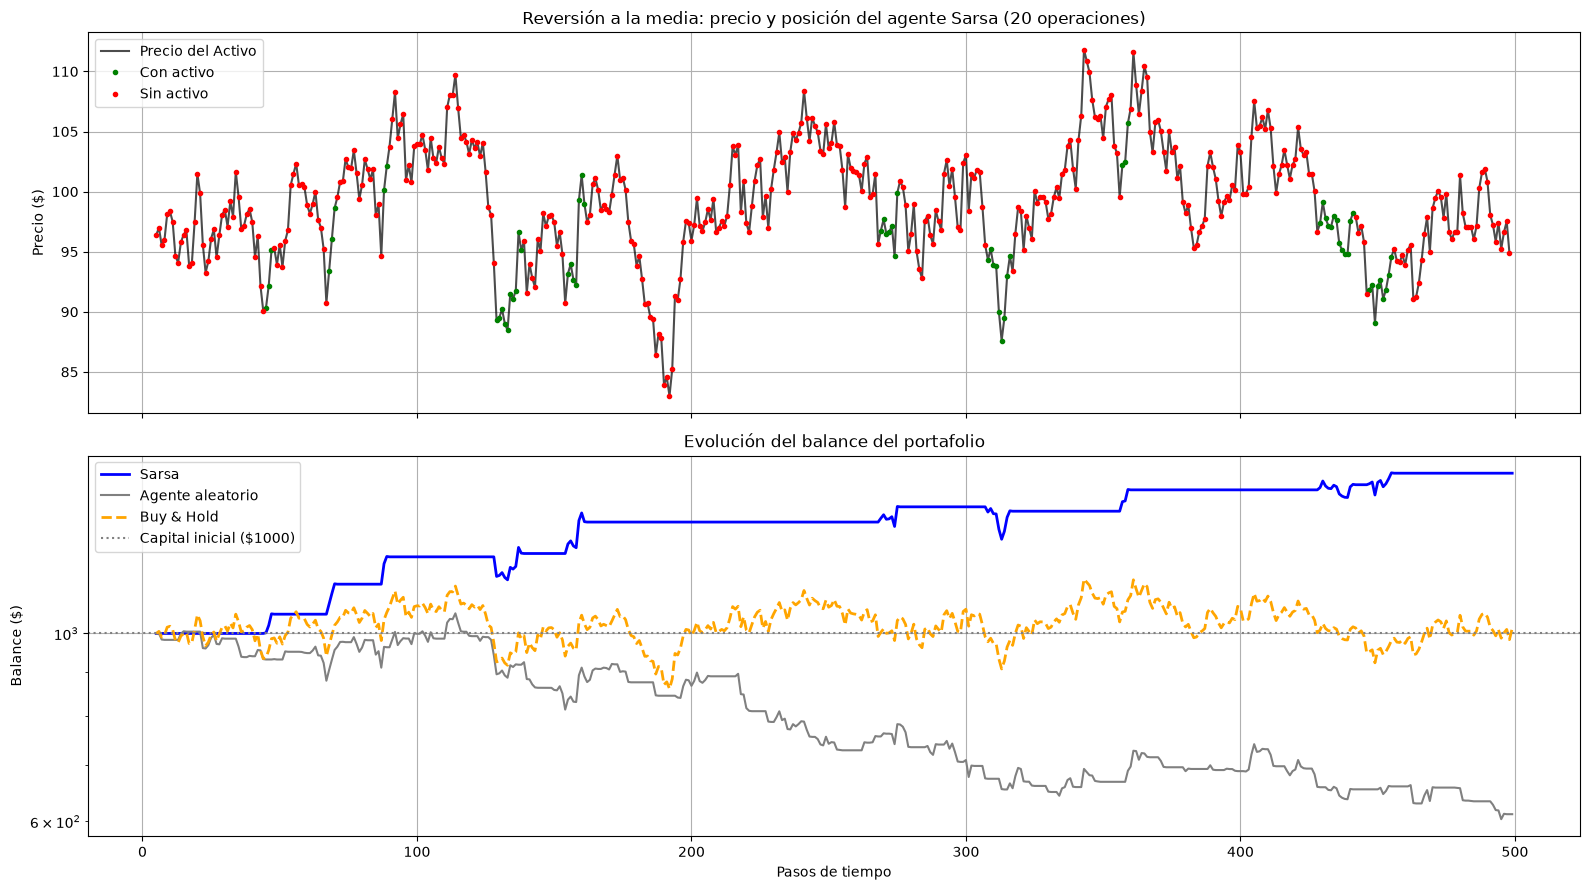

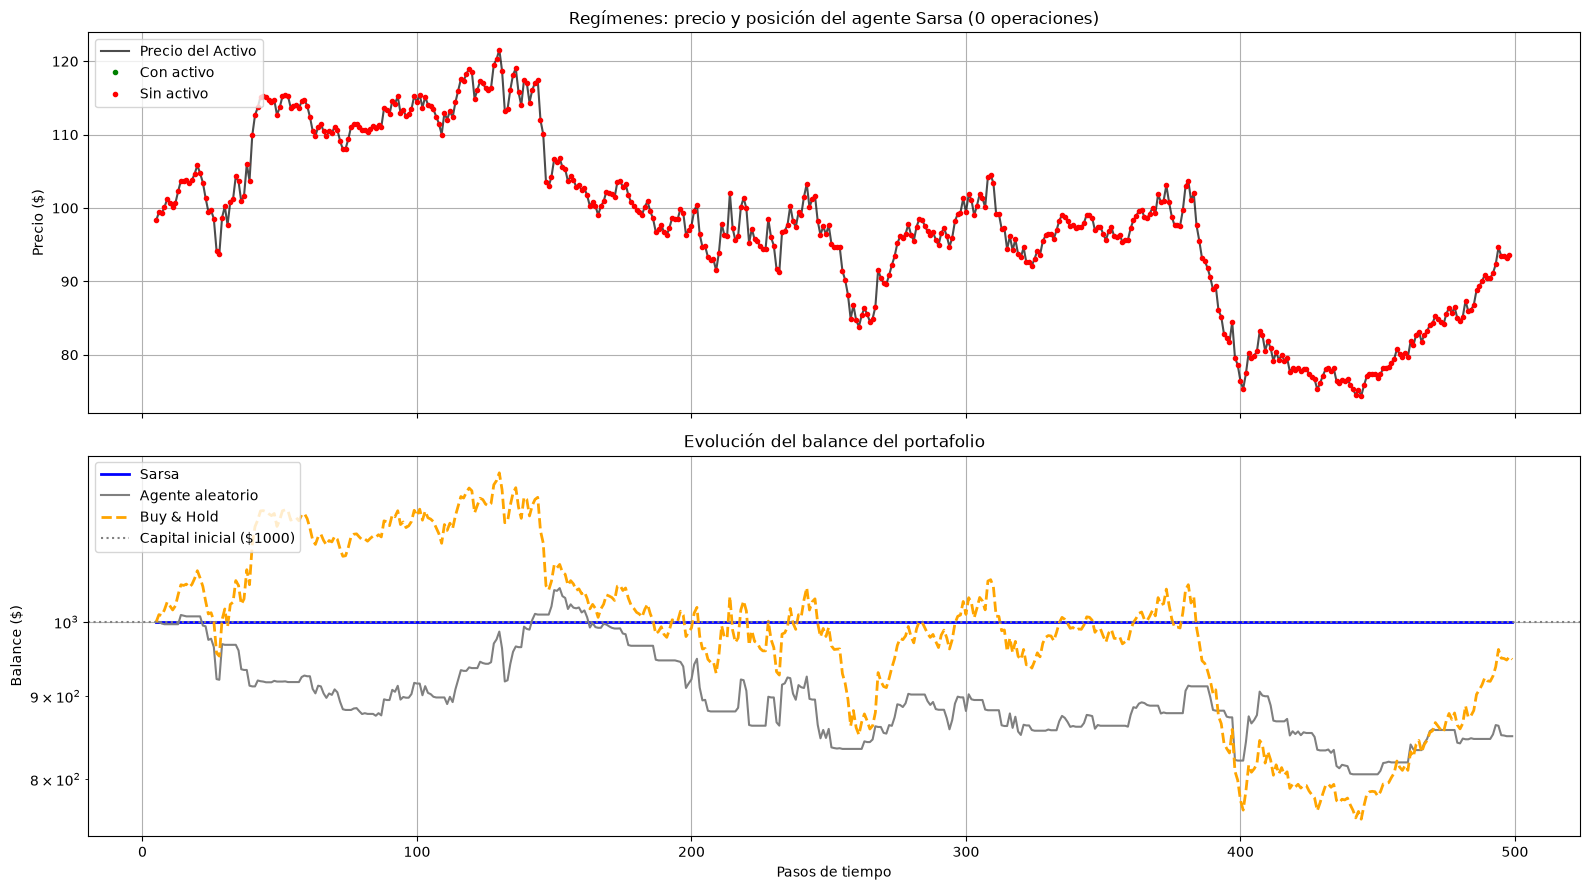

In [26]:
def grafico_episodio(gen, indice=0, agente=None):
    agente = agente or FINALES[gen][0]["agente"]
    precios = SERIES_TEST[gen][indice]
    sarsa = rollout(precios, agente.politica)
    bh = rollout(precios, comprar_y_mantener)
    aleatorio = rollout(precios, PoliticaAleatoria(1))

    valid_prices = precios[5:-1]
    prices_on = valid_prices.copy()
    prices_on[sarsa["posiciones"] == 0] = np.nan
    prices_off = valid_prices.copy()
    prices_off[sarsa["posiciones"] == 1] = np.nan
    pasos = np.arange(5, len(precios))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
    ax1.plot(pasos[:-1], valid_prices, color="black", alpha=0.7, linewidth=1.5, label="Precio del Activo")
    ax1.plot(pasos[:-1], prices_on, "g.", label="Con activo")
    ax1.plot(pasos[:-1], prices_off, "r.", label="Sin activo")
    ax1.set_title(f"{gen}: precio y posición del agente Sarsa ({sarsa['operaciones']} operaciones)")
    ax1.set_ylabel("Precio ($)")
    ax1.legend(loc="upper left")
    ax1.grid(True)

    ax2.plot(pasos, sarsa["balances"], color="blue", linewidth=2, label="Sarsa")
    ax2.plot(pasos, aleatorio["balances"], color="gray", linewidth=1.5, label="Agente aleatorio")
    ax2.plot(pasos, bh["balances"], color="orange", linestyle="--", linewidth=2, label="Buy & Hold")
    ax2.axhline(y=CAPITAL_INICIAL, color="gray", linestyle=":", label="Capital inicial ($1000)")
    ax2.set_title("Evolución del balance del portafolio")
    ax2.set_xlabel("Pasos de tiempo")
    ax2.set_ylabel("Balance ($)")
    ax2.set_yscale("log")
    ax2.legend(loc="upper left")
    ax2.grid(True)
    plt.tight_layout()
    plt.show()


for gen in GENERADORES:
    grafico_episodio(gen)

### ¿Qué estrategia ha aprendido?

Para cada intervalo de tendencia se muestra la **ventaja de cambiar de posición**: sin activo, $Q(\text{comprar})-Q(\text{mantener})$; con activo, $Q(\text{vender})-Q(\text{mantener})$ (media sobre las 5 semillas, en milésimas). Si es positiva el agente cambia de posición en ese estado. Como referencia, el coste de una operación (0,1 %) equivale a 1 en esta escala.

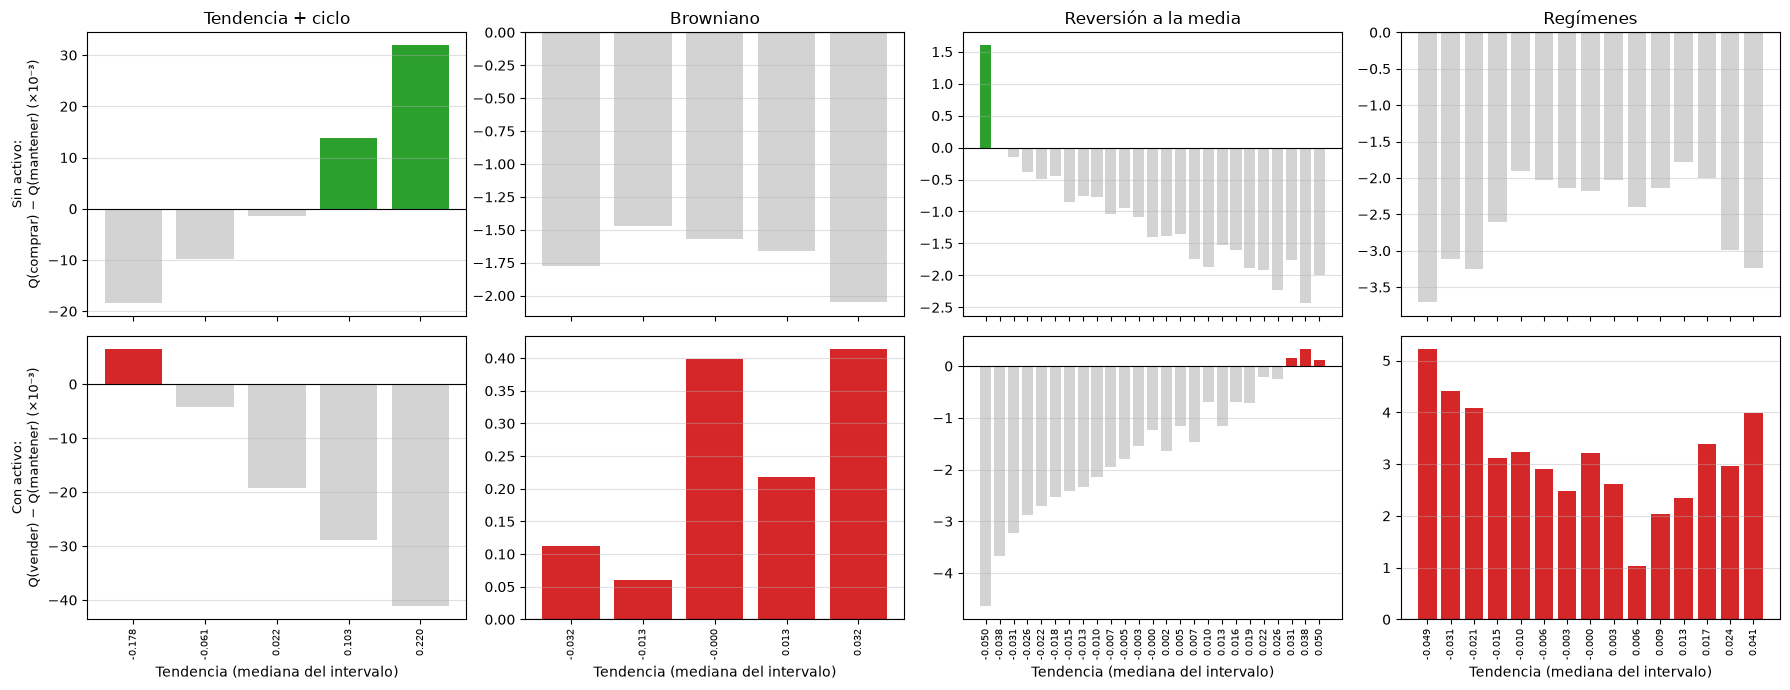

In [27]:
fig, axs = plt.subplots(2, len(GENERADORES), figsize=(18, 7), sharex="col")
for col, gen in enumerate(GENERADORES):
    q = np.mean([o["agente"].tabla_q for o in FINALES[gen]], axis=0)
    disc = FINALES[gen][0]["agente"].disc
    x = np.array(disc.centros, dtype=float)
    ventajas = [("Sin activo: Q(comprar) − Q(mantener)", q[:, 0, 2] - q[:, 0, 1]),
                ("Con activo: Q(vender) − Q(mantener)", q[:, 1, 0] - q[:, 1, 1])]
    for fila, (titulo, v) in enumerate(ventajas):
        ax = axs[fila, col]
        ax.bar(range(len(v)), 1e3 * v, color=np.where(v > 0, "tab:red" if fila else "tab:green", "lightgray"))
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(range(len(v)))
        ax.set_xticklabels([f"{c:.3f}" for c in x], rotation=90, fontsize=7)
        ax.grid(True, axis="y", alpha=0.4)
        if fila == 0:
            ax.set_title(gen)
        if col == 0:
            ax.set_ylabel(titulo.replace(": ", ":\n") + " (×10⁻³)", fontsize=9)
        if fila == 1:
            ax.set_xlabel("Tendencia (mediana del intervalo)")
plt.tight_layout()
plt.show()

### ¿Se generaliza a otros mercados?

Cada agente (semilla 0) se evalúa sobre las series de test de **todos** los generadores. Valor: diferencia entre el retorno logarítmico medio del agente y el de *buy & hold* en las mismas series (positivo = mejor que *buy & hold*). Muestra si lo aprendido es una regularidad específica del tipo de mercado.

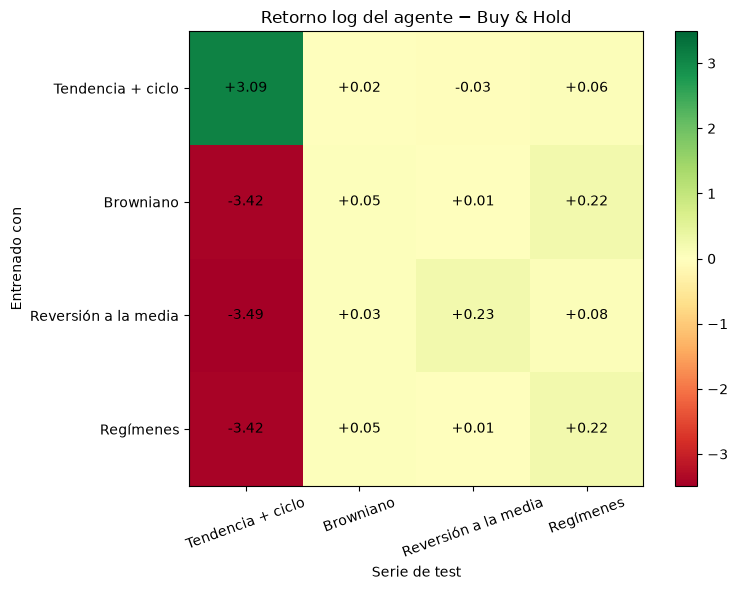

In [28]:
nombres = list(GENERADORES)
transfer = np.zeros((len(nombres), len(nombres)))
for i, entrenado_en in enumerate(nombres):
    agente = FINALES[entrenado_en][0]["agente"]
    for j, probado_en in enumerate(nombres):
        series = SERIES_TEST[probado_en][:100]
        ag = evaluar(agente.politica, series)["final"]
        bh = evaluar(comprar_y_mantener, series)["final"]
        transfer[i, j] = np.log(ag / CAPITAL_INICIAL).mean() - np.log(bh / CAPITAL_INICIAL).mean()

plt.figure(figsize=(8, 6))
lim = np.abs(transfer).max()
plt.imshow(transfer, cmap="RdYlGn", vmin=-lim, vmax=lim)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        plt.text(j, i, f"{transfer[i, j]:+.2f}", ha="center", va="center")
plt.xticks(range(len(nombres)), nombres, rotation=20)
plt.yticks(range(len(nombres)), nombres)
plt.xlabel("Serie de test")
plt.ylabel("Entrenado con")
plt.title("Retorno log del agente − Buy & Hold")
plt.colorbar()
plt.tight_layout()
plt.show()

## 6. Ablaciones: ¿qué decisiones de diseño importan?

Se repite el entrenamiento (3 semillas, `N_EPISODES` episodios, hiperparámetros óptimos de cada generador) cambiando una decisión cada vez, y se mide el retorno logarítmico medio de la política *greedy* en **validación**. La última fila no reentrena: evalúa los agentes finales ejecutando la política $\epsilon$-greedy de entrenamiento ($\epsilon=\epsilon_{final}$) en lugar de la política *greedy*, que es lo que haría un agente *on-policy* que sigue explorando.

In [29]:
SEMILLAS_ABLACION = (0, 1, 2)
VARIANTES = {
    "Sin máscara de acciones": {"mascara": False},
    "α constante": {"alpha_final": None},
    "ε constante (0,1)": {"eps_inicial": 0.1, "eps_final": 0.1},
    "γ = 0": {"gamma": 0.0},
    "γ = 0,95": {"gamma": 0.95},
}

tareas = [dict(gen=gen, params={**MEJORES_PARAMS[gen], **cambio}, n_episodios=N_EPISODES, semilla=s)
          for gen in GENERADORES for cambio in VARIANTES.values() for s in SEMILLAS_ABLACION]
t0 = time.perf_counter()
salidas = ejecutar(tarea_sarsa, tareas)
print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

puntuaciones = {gen: {} for gen in GENERADORES}
k = 0
for gen in GENERADORES:
    puntuaciones[gen]["Sarsa (configuración óptima)"] = [o["hist"]["val_logret"][-1] for o in FINALES[gen]
                                                           if o["semilla"] in SEMILLAS_ABLACION]
    for nombre in VARIANTES:
        puntuaciones[gen][nombre] = [salidas[k + i]["hist"]["val_logret"][-1] for i in range(len(SEMILLAS_ABLACION))]
        k += len(SEMILLAS_ABLACION)
    puntuaciones[gen]["Evaluada con ε-greedy (ε = ε_final)"] = [
        np.log(evaluar(lambda obs, a=o["agente"]: a.elegir_accion(a.disc(obs)), SERIES_VAL[gen])["final"] / CAPITAL_INICIAL).mean()
        for o in FINALES[gen] if o["semilla"] in SEMILLAS_ABLACION]

ablacion = pd.DataFrame({gen: {v: f"{np.mean(x):.3f} ± {np.std(x):.3f}" for v, x in d.items()}
                         for gen, d in puntuaciones.items()})
display(ablacion)

60 entrenamientos en 206 s


,Tendencia + ciclo,Browniano,Reversión a la media,Regímenes
Sarsa (configuración óptima),6.108 ± 0.187,0.000 ± 0.000,0.212 ± 0.015,0.000 ± 0.000
Sin máscara de acciones,6.373 ± 0.000,0.000 ± 0.000,0.187 ± 0.031,0.023 ± 0.033
α constante,5.818 ± 0.468,0.000 ± 0.000,0.030 ± 0.033,0.000 ± 0.000
"ε constante (0,1)",6.373 ± 0.000,0.000 ± 0.000,0.204 ± 0.033,0.000 ± 0.000
γ = 0,6.108 ± 0.187,0.000 ± 0.000,0.212 ± 0.015,0.000 ± 0.000
"γ = 0,95",5.903 ± 0.000,0.000 ± 0.000,0.137 ± 0.014,0.000 ± 0.000
Evaluada con ε-greedy (ε = ε_final),5.499 ± 0.103,-0.053 ± 0.013,0.104 ± 0.037,-0.057 ± 0.006


## 7. Análisis de resultados y conclusiones

Todas las cifras son las de la ejecución de este notebook (semillas fijas; 200 series de test por generador; para Sarsa, media de 5 semillas). Para interpretar la tabla conviene recordar que el balance medio puede engañar en series muy volátiles, por eso se acompaña de la mediana y del retorno logarítmico.

**Tendencia + ciclo.** Es el único mercado con una señal fuerte: la rentabilidad del paso siguiente crece de aproximadamente −2 % a +4,6 % con la tendencia (figura de la sección 2). Sarsa aprende una estrategia de **momentum**: compra con las tendencias más altas, vende con la más baja y mantiene en el resto (gráfica de ventajas), que es lo esperable con una componente cíclica de periodo ≈ 63 pasos. Obtiene un balance mediano de 590 177 $ frente a 35 269 $ de *buy & hold* y 4 072 $ del agente aleatorio, supera a *buy & hold* en el 96 % de las series y opera unas 47 veces por episodio. Converge rápido (≈ 320 episodios hasta el 90 % de la mejora). Salvedad: una volatilidad del 10 % por paso es poco realista y hace que el balance medio dependa de unas pocas series (la desviación entre semillas es del 21 %); el retorno logarítmico y la mediana son más fiables.

**Browniano.** No hay estructura que aprender: la rentabilidad esperada por intervalo (< 0,06 %) está por debajo del coste de una operación y el ruido es del 2 % por paso. Lo racional es no pagar comisiones y Sarsa lo aprende (0 operaciones, balance de 1 000 $), con lo que supera con holgura al agente aleatorio (860 $). Sin embargo **pierde frente a *buy & hold* en balance medio** (1 077 $; diferencia de −77 ± 36 $) mientras que en la mediana (984 $) y en el retorno logarítmico (−0,036) *buy & hold* queda por debajo de no operar. La deriva positiva de este generador solo se cobra en media aritmética; como los hiperparámetros se eligieron con el retorno logarítmico, la selección favorece no operar. Es un resultado esperado, pero depende del criterio de evaluación y conviene discutirlo así.

**Reversión a la media.** Sarsa obtiene un balance medio de 1 260 $ (+26 %) frente a 998 $ de *buy & hold* y lo supera en el 90 % de las series con unas 25 operaciones por episodio. La estrategia es **contraria**: compra tras las mayores caídas y vende tras las mayores subidas, que es lo esperable. Es una señal modesta (+0,24 % tras caídas fuertes frente a un coste de 0,1 %) y está limitada por el estado: la reversión depende de la distancia al precio de equilibrio (100), que el agente no observa; solo ve la tendencia de 6 pasos. Converge más despacio (≈ 1 400 episodios) porque la ventaja por estado es pequeña frente al ruido.

**Regímenes.** *Buy & hold* pierde en media (883 $) porque el régimen bajista tiene más deriva negativa y más volatilidad que lo que el alcista aporta, y el agente aleatorio aún más (795 $). Sarsa aprende a **no operar** (0 operaciones, 1 000 $, +117 ± 28 $ sobre *buy & hold*). Es una estrategia defensiva, no una detección de regímenes: la tendencia de 6 pasos no distingue bien el régimen (rentabilidad esperada por intervalo como mucho +0,05 %, por debajo del coste, y negativa en los extremos). Detectarlo requeriría una variable que el estado no incluye, como la volatilidad reciente (2,5 % en el régimen bajista frente a 1 % en el alcista).

**Hiperparámetros.**

- **$\alpha$.** Lo mejor es una tasa baja y decreciente. Con $\alpha$ constante la ablación empeora (Reversión a la media: 0,030 frente a 0,212; Tendencia + ciclo: 5,82 ± 0,47 frente a 6,11 ± 0,19). Con ruido del 2 % por paso y señales de 0,1–0,2 %, un $\alpha$ constante deja en las estimaciones de $Q$ un ruido del mismo orden que la señal.
- **$\gamma$.** No hay un valor claramente mejor: en la búsqueda $\gamma=0{,}9$ promedia mejor en Reversión a la media, pero las mejores configuraciones individuales usan $\gamma=0$, y en la ablación $\gamma=0$ supera a $\gamma=0{,}95$ (0,212 frente a 0,137 en Reversión a la media). Una explicación plausible es que la recompensa ya contiene el efecto de la posición sobre el paso siguiente y el estado incluye la posición, así que apoyarse en el valor del estado siguiente añade más ruido que información.
- **$\epsilon$.** El calendario no es crítico: un $\epsilon$ constante de 0,1 da resultados parecidos (6,373 y 0,204). Hay muchas visitas por par estado-acción y solo dos acciones relevantes por estado.
- **Acciones válidas (máscara).** No es decisiva (Reversión a la media: 0,187 sin máscara frente a 0,212 con ella, diferencia comparable al ruido entre semillas) pero tampoco perjudica.
- **Número de intervalos.** Depende del mercado: las mejores configuraciones usan 5 en Tendencia + ciclo (señal fuerte y monótona) y 25 en Reversión a la media (señal concentrada en las colas). No hay una tendencia monótona en la búsqueda (en Reversión a la media 15 intervalos rinden peor que 9 o 25), así que es un parámetro ruidoso.
- En Tendencia + ciclo las diferencias entre configuraciones son comparables al ruido entre semillas (varias variantes de la ablación superan a la configuración "óptima", que fue elegida entre muchas con validación): la selección sufre algo de *winner's curse*.

**Sarsa es *on-policy*.** Ejecutar la política $\epsilon$-greedy con la que se entrena ($\epsilon=\epsilon_{final}$) en lugar de la política *greedy* empeora el resultado (6,108 → 5,499 en Tendencia + ciclo; 0,212 → 0,104 en Reversión a la media; 0,000 → −0,05 en los mercados donde el agente no opera, porque cada acción aleatoria cuesta una comisión). Es lo que predice la teoría: Sarsa converge a la mejor política $\epsilon$-greedy y es la política *greedy* la que debe desplegarse. Aquí no hay un "acantilado" (una exploración mala solo cuesta una comisión), así que desplegar la política *greedy* es seguro.

**Transferencia.** La ventaja *aprendida* sobre *buy & hold* solo aparece en el mercado con el que se entrenó (Tendencia + ciclo y Reversión a la media). Los agentes de los mercados sin señal explotable no operan y por eso quedan muy por debajo de *buy & hold* en Tendencia + ciclo (≈ −3,4); en el resto sus diferencias van de −0,03 a +0,23, y el +0,22 en Regímenes lo consigue igual un agente entrenado en Browniano porque consiste simplemente en no operar.

**Coste computacional.** Sarsa tabular es muy barato: del orden de 7 ms por episodio de 500 pasos (los tiempos de la tabla están medidos con 15 procesos simultáneos y son por tanto mayores). La mayor parte del tiempo del notebook se va en el ajuste de hiperparámetros.

**Limitaciones y mejoras posibles**

- El estado (tendencia a 6 pasos y posición) limita lo que se puede aprender. Ampliarlo con la volatilidad reciente y la distancia a una media larga es la mejora más prometedora para Regímenes y Reversión a la media (pruebas preliminares fuera de este notebook apuntan en esa dirección).
- Hay que comprobar que los resultados no dependen de la forma de discretizar (por ejemplo, otros números de intervalos o discretización uniforme).
- Además del retorno, convendría medir el riesgo (volatilidad del balance, *drawdown*, ratio de Sharpe) y probar con series de precios reales.

## 8. Cómo añadir Q-Learning a este notebook

La infraestructura de las secciones 1 y 2 y las funciones `evaluar`, `resumen`, `entrenar_agente`, `episodios_convergencia` y `tabla_resultados` no dependen del algoritmo:

1. Definir `AgenteQLearning(AgenteTabular)` con su `entrenar_episodio`. Se diferencia de Sarsa en que el objetivo es $R+\gamma\max_{a'}Q(S',a')$ sobre las acciones válidas del estado siguiente, y en que la acción $A'$ se elige al comienzo del paso siguiente y no antes de actualizar.
2. Repetir el ajuste de hiperparámetros y el entrenamiento final con esa clase (`tarea_sarsa` solo necesita cambiar `AgenteSarsa` por la nueva clase).
3. Guardar los resultados con las mismas claves, `RESULTADOS[(gen, "Q-Learning")] = ...`, y volver a llamar a `tabla_resultados(RESULTADOS)`.

Conviene usar las mismas series de validación y de test (`SEED_VAL`, `SEED_TEST`) para que la comparación entre algoritmos sea pareada.